Import libraries

In [1]:
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import folium
from folium import GeoJsonTooltip

Import Class

In [2]:
import sys
sys.path.insert(0, '..')

from src.fetcher import SSBcsvFetcher

fetcher = SSBcsvFetcher()

Search for table

In [3]:
# Search for specific tables
befolkning = fetcher.search_tables('befolkning') # random example
befolkning[['id', 'description']].head(20)

INFO:src.inspector:Searching for tables: befolkning
INFO:src.inspector:Found 20 matching tables


,id,description
0,13930,
1,14476,
2,07519,
3,12631,
4,05803,
5,14483,
6,13760,
7,12871,
8,10211,
9,05813,


Print out information

In [4]:
# Print nicely formatted info
fetcher.print_table_info('11342')

INFO:src.inspector:Fetching info for table 11342



Table ID: 11342
Title: 11342: Areal og befolkning i kommuner, fylker og hele landet (K) 2007-2025

Variables: region, statistikkvariabel, år
Time Unit: Annual
Period: 2007 - 2025
Last Updated: 2025-02-26T07:00:00Z
Source: Statistisk sentralbyrå



Inspect filters

In [5]:
# See what filters are available
fetcher.print_dimensions('11342')

# Get dimension details for Region
dimensions = fetcher.get_dimensions('11342')
region_values = dimensions['Region']['values']

# Display as DataFrame for easier viewing
region_df = pd.DataFrame(list(region_values.items()), columns=['Code', 'Name'])
print(region_df.to_string())

INFO:src.api:Fetching dimensions for table 11342
INFO:src.api:Fetching dimensions for table 11342



Available filters for table 11342:

region (Region):
  ['0', '31', '3101', '3103', '3105', '3107', '3110', '3112', '3114', '3116']
  ... and 969 more

statistikkvariabel (ContentsCode):
  Folkemengde: Befolkning per 1.1. (personer)
  ArealKm2: Areal (km²)
  LandArealKm2: Landareal (km²)
  FolkeLandArealKm2: Innbyggere per km² landareal

år (Tid):
  ['2007', '2008', '2009', '2010', '2011', '2012', '2013', '2014', '2015', '2016']
  ... and 9 more


      Code                                                Name
0        0                                         Hele landet
1       31                                             Østfold
2     3101                                              Halden
3     3103                                                Moss
4     3105                                           Sarpsborg
5     3107                                         Fredrikstad
6     3110                                              Hvaler
7     3112                                  

Fetch county df

In [6]:
# Fetch data for specific regions and year 2025
regions = ['31', '32', '03', '33', '34', '39', '40', '42', '11', '46', '15', '50', '18', '55', '56']

df = fetcher.fetch_clean_table(
    '11342',
    time_period='2025',
    filters={
        'Region': ','.join(regions),
        'ContentsCode': 'Folkemengde'
    }
)

df

INFO:src.api:Fetching dimensions for table 11342
INFO:src.api:Fetching pivot table 11342
INFO:src.api:URL: https://data.ssb.no/api/pxwebapi/v2/tables/11342/data?lang=no&outputformat=csv&outputformatparams=separatorsemicolon,usecodesandtexts&stub=Tid&heading=statistikkvariabel&valuecodes[Tid]=2025&valuecodes[Region]=31%2C32%2C03%2C33%2C34%2C39%2C40%2C42%2C11%2C46%2C15%2C50%2C18%2C55%2C56&valuecodes[ContentsCode]=Folkemengde
INFO:src.api:Successfully fetched 15 rows


,region,2025
0,31 Østfold,314407
1,32 Akershus,740680
2,Oslove,724290
3,33 Buskerud,271248
4,34 Innlandet,377556
5,39 Vestfold,258071
6,40 Telemark,177863
7,42 Agder,322188
8,11 Rogaland,504496
9,46 Vestland,655210


Clean DataFrame (pandas)

In [7]:

# Remove region codes from region column using a regular expression
df['region'] = df['region'].str.replace(r'^\d+\s+', '', regex=True).str.strip()

# Rename specific regions
rename_map = {
    'Oslove': 'Oslo',
    'Trööndelage': 'Trøndelag',
    'Nordlánnda': 'Nordland',
    'Tromssa': 'Troms',
    'Finmarkku': 'Finnmark'
}

df['region'] = df['region'].replace(rename_map)

df

,region,2025
0,Østfold,314407
1,Akershus,740680
2,Oslo,724290
3,Buskerud,271248
4,Innlandet,377556
5,Vestfold,258071
6,Telemark,177863
7,Agder,322188
8,Rogaland,504496
9,Vestland,655210


Read (geojson) DataFrame

In [8]:
# read geojson file using geopandas
gdf = gpd.read_file(r'C:\Users\matia\Desktop\ssb\maps\borders\Fylker-L.geojson')

Print out the shapes using matplotlib

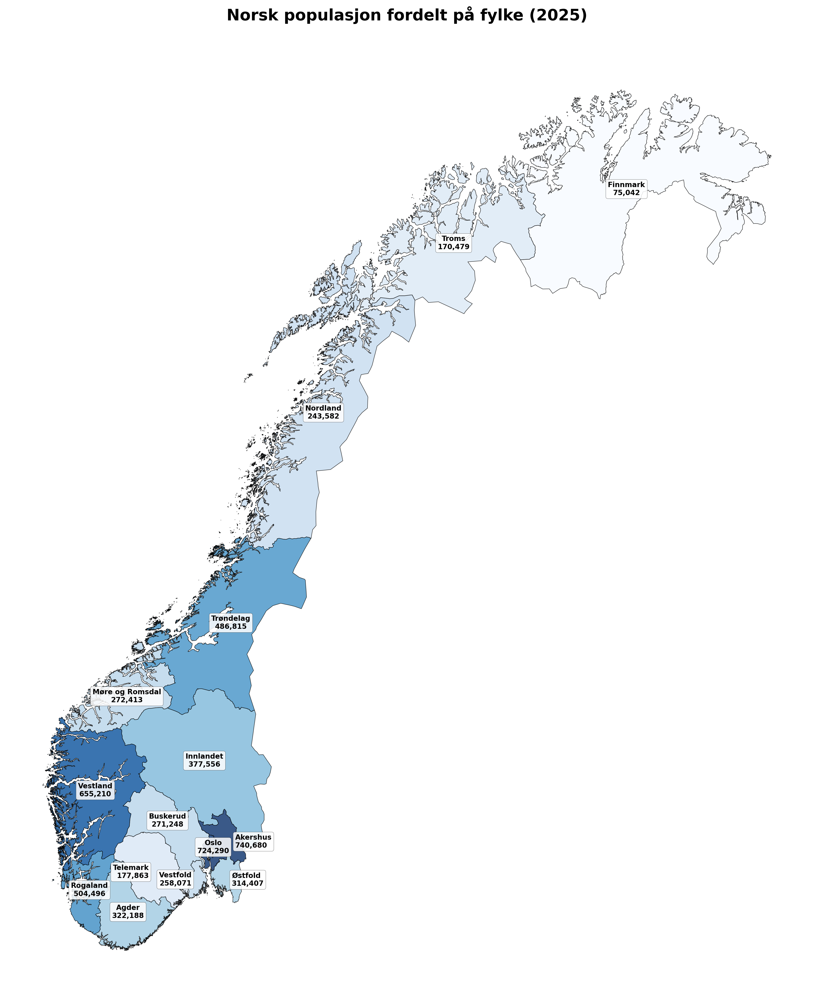

In [11]:
# Set matplotlib parameters for better quality
plt.rcParams['figure.dpi'] = 300
plt.rcParams['savefig.dpi'] = 300
plt.rcParams['font.size'] = 12

# Create figure and axis with improved settings
fig, ax = plt.subplots(1, 1, figsize=(26, 16))

# Merge data with geodataframe
gdf_merged = gdf.merge(df, left_on='name', right_on='region', how='left')

# Reproject to a flat projection (Web Mercator or equal area)
gdf_merged = gdf_merged.to_crs('EPSG:3857')  # Web Mercator (flat)

# Merge data with geodataframe
gdf_merged = gdf.merge(df, left_on='name', right_on='region', how='left')

# Convert '2025' column to numeric
gdf_merged['2025'] = pd.to_numeric(gdf_merged['2025'], errors='coerce')

# Reproject to a flat projection (Web Mercator or equal area)
gdf_merged = gdf_merged.to_crs('EPSG:3857')  # Web Mercator (flat)

# Create the choropleth using matplotlib's colormap with improved styling
gdf_merged.plot(
    column='2025',
    ax=ax,
    legend=False,
    missing_kwds={'color': 'lightgrey', 'alpha': 0.5},
    cmap=plt.cm.Blues,
    edgecolor='black',
    linewidth=0.5,
    alpha=0.8
)

# Customize the plot
plt.title('Norsk populasjon fordelt på fylke (2025)', 
          pad=30, 
          fontsize=18, 
          fontweight='bold')

# Add text labels with region name and population
# Add text labels with region name and population (improved positioning to avoid overlaps)
for idx, row in gdf_merged.iterrows():
    centroid = row.geometry.centroid
    region_name = row['region']
    population = row['2025']
    if pd.notna(population):
        
        # Special positioning for specific counties to avoid overlaps
        if region_name == 'Akershus':
            label_x = centroid.x + 50000
            label_y = centroid.y
            ha = 'left'
        elif region_name == 'Oslo':
            label_x = centroid.x
            label_y = centroid.y - 15000
            ha = 'center'
        elif region_name == 'Vestfold':
            label_x = centroid.x - 20000
            label_y = centroid.y
            ha = 'right'
        elif region_name == 'Østfold':
            label_x = centroid.x + 15000
            label_y = centroid.y - 10000
            ha = 'left'
        elif region_name == 'Buskerud':
            label_x = centroid.x
            label_y = centroid.y + 20000
            ha = 'center'
        elif region_name == 'Telemark':
            label_x = centroid.x - 15000
            label_y = centroid.y - 15000
            ha = 'right'
        else:
            # Default positioning for other counties
            label_x = centroid.x
            label_y = centroid.y
            ha = 'center'
        
        label_text = f"{region_name}\n{int(population):,}"
        plt.text(label_x, label_y,
                label_text,
                ha=ha,
                va='center',
                fontsize=8,
                weight='bold',
                bbox=dict(facecolor='white', 
                         alpha=0.85,
                         edgecolor='black',
                         linewidth=0.2,
                         pad=1.5,
                         boxstyle='round,pad=0.3'))

# Remove axes for cleaner look
ax.set_axis_off()
ax.set_aspect('equal')

plt.box(False)
plt.subplots_adjust(right=0.95)
plt.tight_layout()
plt.show()

Apply borders to folium map

In [10]:
# Prepare the data for folium
gdf_for_folium = gdf_merged.copy(deep=True)
gdf_for_folium = gdf_for_folium.to_crs('EPSG:4326')

# Create base map
m = folium.Map(
    location=[60.5, 10.5],
    zoom_start=4,
    tiles='CartoDB positron'
)

# Convert GeoDataFrame to GeoJSON
geo_json = gdf_for_folium.to_json()

# Create choropleth with black borders
folium.Choropleth(
    geo_data=geo_json,
    data=gdf_for_folium,
    columns=['region', '2025'],
    key_on='feature.properties.region',
    fill_color='Blues',
    fill_opacity=0.8,
    color='black',
    weight=0.5,
    legend_name='Populasjon'
).add_to(m)

# Add hover tooltips
folium.features.GeoJson(
    geo_json,
    style_function=lambda x: {'fillOpacity': 0, 'color': 'transparent'},
    tooltip=GeoJsonTooltip(fields=['region', '2025'], aliases=['Fylke:', 'Populasjon:'])
).add_to(m)

# Auto-fit map to bounds
m.fit_bounds(m.get_bounds())
m